Analyze NYC Yellow Taxi trip data using Python, Pandas, and SQL to clean and explore millions of trips, identify patterns in demand, fares, times, and locations, visualize key findings, and build a machine-learning model to predict taxi fares.

In [303]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [304]:
%pip install pyarrow


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [305]:

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-01.parquet"

df = pd.read_parquet(url, engine="pyarrow")
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.00,0.97,1.00,N,239,238,1,7.20,1.00,0.50,3.66,0.00,1.00,15.86,2.50,0.00,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.00,0.90,1.00,N,163,162,2,7.90,4.25,0.50,0.00,0.00,1.00,13.65,2.50,0.00,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.00,1.40,1.00,N,43,237,1,10.70,4.25,0.50,2.50,0.00,1.00,18.95,2.50,0.00,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.00,5.58,1.00,N,142,209,1,38.70,1.00,0.50,11.11,0.00,1.00,55.56,2.50,0.00,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.00,2.16,1.00,N,88,144,1,13.50,1.00,0.50,3.85,0.00,1.00,23.10,2.50,0.00,0.75


In [306]:
type(df)

pandas.core.frame.DataFrame

In [307]:
#load first 5 lines of table for preview
df.head(5)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.00,0.97,1.00,N,239,238,1,7.20,1.00,0.50,3.66,0.00,1.00,15.86,2.50,0.00,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.00,0.90,1.00,N,163,162,2,7.90,4.25,0.50,0.00,0.00,1.00,13.65,2.50,0.00,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.00,1.40,1.00,N,43,237,1,10.70,4.25,0.50,2.50,0.00,1.00,18.95,2.50,0.00,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.00,5.58,1.00,N,142,209,1,38.70,1.00,0.50,11.11,0.00,1.00,55.56,2.50,0.00,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.00,2.16,1.00,N,88,144,1,13.50,1.00,0.50,3.85,0.00,1.00,23.10,2.50,0.00,0.75


In [308]:
#to view numbers rows,columns
df.shape

(3724889, 20)

In [309]:
#look at all the variables that can effect the outcome
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee'],
      dtype='object')

In [310]:
#see what type of information each column holds
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3724889 entries, 0 to 3724888
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [311]:
#get summery of statsitics
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,"3,724,889.00",3724889,3724889,"2,636,831.00","3,724,889.00","2,636,831.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","2,636,831.00","2,636,831.00","3,724,889.00"
mean,1.87,2026-01-17 01:44:52.106518,2026-01-17 02:02:03.696138,1.26,6.46,5.22,161.44,160.99,0.85,20.80,1.02,0.48,2.61,0.50,0.95,29.18,2.15,0.15,0.52
min,1.00,2025-12-31 23:57:29,2025-12-31 23:57:32,0.00,0.00,1.00,1.00,1.00,0.00,"-2,555.20",-7.50,-0.50,-88.88,-94.50,-1.00,"-2,560.20",-2.50,-1.75,-0.75
25%,2.00,2026-01-09 17:51:59,2026-01-09 18:08:47,1.00,1.00,1.00,114.00,107.00,0.00,10.00,0.00,0.50,0.00,0.00,1.00,17.00,2.50,0.00,0.00
50%,2.00,2026-01-16 21:20:56,2026-01-16 21:36:14,1.00,1.81,1.00,161.00,162.00,1.00,15.60,0.00,0.50,2.00,0.00,1.00,23.05,2.50,0.00,0.75
75%,2.00,2026-01-24 07:25:11,2026-01-24 07:40:22,1.00,3.73,1.00,233.00,234.00,1.00,26.10,2.50,0.50,3.71,0.00,1.00,33.83,2.50,0.00,0.75
max,7.00,2026-02-01 00:45:01,2026-02-01 23:35:31,9.00,"269,097.48",99.00,265.00,265.00,4.00,"2,555.20",17.46,4.75,766.00,122.22,1.00,"2,560.20",2.50,26.75,0.75
std,0.70,NaN,NaN,0.67,648.89,19.65,67.07,71.04,0.71,18.93,1.71,0.11,3.92,2.13,0.27,22.59,0.94,0.53,0.36


In [312]:
#so that the numbers are easier to read, we can set the display format for floats
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [313]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.00,0.97,1.00,N,239,238,1,7.20,1.00,0.50,3.66,0.00,1.00,15.86,2.50,0.00,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.00,0.90,1.00,N,163,162,2,7.90,4.25,0.50,0.00,0.00,1.00,13.65,2.50,0.00,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.00,1.40,1.00,N,43,237,1,10.70,4.25,0.50,2.50,0.00,1.00,18.95,2.50,0.00,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.00,5.58,1.00,N,142,209,1,38.70,1.00,0.50,11.11,0.00,1.00,55.56,2.50,0.00,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.00,2.16,1.00,N,88,144,1,13.50,1.00,0.50,3.85,0.00,1.00,23.10,2.50,0.00,0.75


In [314]:
#only select wanted columns to make eaiser
df[
    [
       "passenger_count",
        "trip_distance",
        "fare_amount",
        "tip_amount",
        "total_amount"
    ]



].describe()

,passenger_count,trip_distance,fare_amount,tip_amount,total_amount
count,"2,636,831.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00"
mean,1.26,6.46,20.80,2.61,29.18
std,0.67,648.89,18.93,3.92,22.59
min,0.00,0.00,"-2,555.20",-88.88,"-2,560.20"
25%,1.00,1.00,10.00,0.00,17.00
50%,1.00,1.81,15.60,2.00,23.05
75%,1.00,3.73,26.10,3.71,33.83
max,9.00,"269,097.48","2,555.20",766.00,"2,560.20"


In [315]:
#check for missing data
df.isna().sum()

VendorID                       0
tpep_pickup_datetime           0
tpep_dropoff_datetime          0
passenger_count          1088058
trip_distance                  0
RatecodeID               1088058
store_and_fwd_flag       1088058
PULocationID                   0
DOLocationID                   0
payment_type                   0
fare_amount                    0
extra                          0
mta_tax                        0
tip_amount                     0
tolls_amount                   0
improvement_surcharge          0
total_amount                   0
congestion_surcharge     1088058
Airport_fee              1088058
cbd_congestion_fee             0
dtype: int64

In [316]:
#check percentages of missing values
missing_percent = df.isna().mean() * 100
missing_percent.sort_values(ascending=False)

Airport_fee             29.21
passenger_count         29.21
congestion_surcharge    29.21
RatecodeID              29.21
store_and_fwd_flag      29.21
VendorID                 0.00
mta_tax                  0.00
total_amount             0.00
improvement_surcharge    0.00
tolls_amount             0.00
tip_amount               0.00
fare_amount              0.00
extra                    0.00
tpep_pickup_datetime     0.00
payment_type             0.00
DOLocationID             0.00
PULocationID             0.00
trip_distance            0.00
tpep_dropoff_datetime    0.00
cbd_congestion_fee       0.00
dtype: float64

In [317]:
#make a df with columns needed
columns_needed = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "PULocationID",
    "DOLocationID",
    "payment_type",
    "fare_amount",
    "tip_amount",
    "total_amount"
]

df_clean = df[columns_needed].copy()

In [318]:
df_clean.head(10)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount
0,2026-01-01 00:54:04,2026-01-01 00:59:37,1.00,0.97,239,238,1,7.20,3.66,15.86
1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.00,0.90,163,162,2,7.90,0.00,13.65
2,2026-01-01 00:57:06,2026-01-01 01:05:59,0.00,1.40,43,237,1,10.70,2.50,18.95
3,2026-01-01 00:15:22,2026-01-01 00:58:10,4.00,5.58,142,209,1,38.70,11.11,55.56
4,2026-01-01 00:27:13,2026-01-01 00:40:43,0.00,2.16,88,144,1,13.50,3.85,23.10
5,2026-01-01 00:47:11,2026-01-01 01:00:47,2.00,2.33,144,137,1,14.20,4.99,24.94
6,2026-01-01 00:17:54,2026-01-01 00:28:32,1.00,1.30,142,50,2,11.40,0.00,17.15
7,2026-01-01 00:34:28,2026-01-01 00:59:05,0.00,2.90,50,234,1,22.60,5.65,34.00
8,2026-01-01 00:34:14,2026-01-01 01:11:58,1.00,5.34,161,45,1,37.30,8.61,51.66
9,2026-01-01 00:41:07,2026-01-01 00:50:42,3.00,1.83,237,263,1,10.70,2.36,18.06


In [319]:
#how many rows we will start with before cleaning
len(df_clean)

3724889

In [320]:
#save for later
original_rows = len(df_clean)

print("Original rows:", original_rows)

Original rows: 3724889


In [321]:
df_clean['trip_distance'].sort_values(ascending=False)

3524923   269,097.48
3632367   237,567.19
3285750   236,216.69
3131676   236,183.06
2704619   221,544.91
             ...    
3011536         0.00
3259810         0.00
3259809         0.00
2841643         0.00
3553287         0.00
Name: trip_distance, Length: 3724889, dtype: float64

In [322]:
df_clean.nlargest(12, 'trip_distance')

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount
3524923,2026-01-28 01:08:00,2026-01-28 01:16:00,NaN,"269,097.48",79,144,0,12.19,0.00,16.94
3632367,2026-01-30 13:00:00,2026-01-30 13:38:00,NaN,"237,567.19",42,130,0,72.99,0.00,81.95
3285750,2026-01-21 16:31:00,2026-01-21 16:40:00,NaN,"236,216.69",234,107,0,13.58,3.00,21.33
3131676,2026-01-17 10:40:00,2026-01-17 10:57:00,NaN,"236,183.06",137,82,0,22.75,0.00,34.96
2704619,2026-01-02 21:31:00,2026-01-02 21:55:00,NaN,"221,544.91",249,41,0,31.21,0.00,39.55
2688274,2026-01-02 07:07:00,2026-01-02 07:18:00,NaN,"221,436.73",231,161,0,27.61,0.00,32.36
3131406,2026-01-17 10:39:00,2026-01-17 10:56:00,NaN,"196,490.48",13,162,0,33.59,0.00,38.34
3571687,2026-01-29 07:51:00,2026-01-29 08:26:00,NaN,"192,081.68",33,246,0,60.20,0.00,64.95
2820951,2026-01-07 17:51:00,2026-01-07 17:56:00,NaN,"184,908.33",164,186,0,12.18,0.00,16.93
3499856,2026-01-27 14:46:00,2026-01-27 16:10:00,NaN,"183,363.75",230,74,0,71.01,0.00,75.76


In [323]:
#look at the quantiles before deciding where to make a cutoff of physically impossible trips
df_clean['trip_distance'].quantile([0.5, 0.75, 0.9, 0.95, .99, .999])

0.50    1.81
0.75    3.73
0.90    8.56
0.95   12.45
0.99   19.54
1.00   29.79
Name: trip_distance, dtype: float64

In [324]:
#create trip duration in minutes
df_clean["trip_duration_minutes"]=(df_clean["tpep_dropoff_datetime"] - df_clean["tpep_pickup_datetime"]).dt.total_seconds() / 60


In [325]:
df_clean[
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_duration_minutes"
    ]
].head(6)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes
0,2026-01-01 00:54:04,2026-01-01 00:59:37,5.55
1,2026-01-01 00:34:04,2026-01-01 00:39:47,5.72
2,2026-01-01 00:57:06,2026-01-01 01:05:59,8.88
3,2026-01-01 00:15:22,2026-01-01 00:58:10,42.80
4,2026-01-01 00:27:13,2026-01-01 00:40:43,13.50
5,2026-01-01 00:47:11,2026-01-01 01:00:47,13.60


In [326]:
df_clean["trip_duration_minutes"].describe()

count   3,724,889.00
mean           17.19
std            25.18
min           -11.70
25%             8.07
50%            13.37
75%            21.20
max         7,507.90
Name: trip_duration_minutes, dtype: float64

In [327]:
df_clean[
    "trip_duration_minutes"
].quantile([0.50, 0.90, 0.95, 0.99, 0.999])

0.50    13.37
0.90    32.25
0.95    42.75
0.99    71.43
1.00   125.79
Name: trip_duration_minutes, dtype: float64

In [ ]:
#check for impossible values 
print(
    "Zero or negative distance:",
    (df_clean["trip_distance"] <= 0).sum()
)

print(
    "Zero or negative duration:",
    (df_clean["trip_duration_minutes"] <= 0).sum()
)

print(
    "Negative fare:",
    (df_clean["fare_amount"] < 0).sum()
)

print(
    "Zero or negative total amount:",
    (df_clean["total_amount"] <= 0).sum()
)

Zero or negative distance: 125738
Zero or negative duration: 45070
Negative fare: 39463
Zero or negative total amount: 40417


In [329]:
#lets take a look at negative fairs
df_clean[df_clean["fare_amount"] < 0].head(10)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount,trip_duration_minutes
74,2026-01-01 00:54:05,2026-01-01 00:56:36,1.00,0.63,143,143,4,-5.10,0.00,-10.10,2.52
248,2026-01-01 00:43:29,2026-01-01 01:09:26,1.00,1.92,170,79,4,-22.60,0.00,-28.35,25.95
368,2026-01-01 00:37:39,2026-01-01 00:38:17,1.00,0.02,261,261,4,-3.00,0.00,-8.75,0.63
428,2026-01-01 00:01:24,2026-01-01 00:02:02,1.00,0.03,162,162,4,-3.00,0.00,-8.75,0.63
649,2026-01-01 00:10:13,2026-01-01 00:35:15,3.00,3.12,161,263,2,-22.60,0.00,-28.35,25.03
871,2026-01-01 00:33:23,2026-01-01 00:40:16,3.00,1.03,238,239,4,-8.60,0.00,-13.60,6.88
980,2025-12-31 23:57:29,2025-12-31 23:57:32,2.00,0.01,132,264,3,-70.00,0.00,-71.50,0.05
1046,2026-01-01 00:01:52,2026-01-01 00:04:22,2.00,0.14,234,234,3,-3.70,0.00,-9.45,2.50
1076,2026-01-01 00:24:04,2026-01-01 00:36:44,1.00,3.63,263,168,2,-17.70,0.00,-22.70,12.67
1106,2026-01-01 00:30:51,2026-01-01 00:31:00,1.00,0.01,239,239,4,-3.00,0.00,-8.00,0.15


In [330]:
#since we only want jan 2026 resrtict data set to such
df_clean = df_clean[
    (df_clean["tpep_pickup_datetime"] >= "2026-01-01")
    &
    (df_clean["tpep_pickup_datetime"] < "2026-02-01")
].copy()

In [331]:
#clean all with basic logic and reasoning for rules (being generous with times given)
df_clean = df_clean[
    (df_clean["trip_distance"] > 0)
    &
    (df_clean["trip_distance"] <= 100)
    &
    (df_clean["trip_duration_minutes"] > 0)
    &
    (df_clean["trip_duration_minutes"] <= 180)
    &
    (df_clean["fare_amount"] > 0)
    &
    (df_clean["total_amount"] > 0)
    &
    (df_clean["passenger_count"] > 0)
].copy()

In [332]:
#look to see how much data we removed
clean_rows = len(df_clean)
rows_removed = original_rows - clean_rows
percent_removed = (rows_removed / original_rows) * 100
print("Original rows:", original_rows)
print("Clean rows:", clean_rows)
print("Rows removed:", rows_removed)
print("Percent removed:", round(percent_removed, 2), "%")

Original rows: 3724889
Clean rows: 2506396
Rows removed: 1218493
Percent removed: 32.71 %


In [333]:
#lets look at new cleaned data
df_clean.describe()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount,trip_duration_minutes
count,2506396,2506396,"2,506,396.00","2,506,396.00","2,506,396.00","2,506,396.00","2,506,396.00","2,506,396.00","2,506,396.00","2,506,396.00","2,506,396.00"
mean,2026-01-16 15:56:03.122538,2026-01-16 16:12:55.615527,1.26,3.44,165.36,165.12,1.16,19.48,3.58,28.96,16.87
min,2026-01-01 00:00:02,2026-01-01 00:02:02,1.00,0.01,1.00,1.00,1.00,0.01,0.00,0.70,0.02
25%,2026-01-09 11:39:26.750000,2026-01-09 11:56:09.750000,1.00,0.98,132.00,114.00,1.00,8.60,1.00,16.38,7.50
50%,2026-01-16 09:35:05.500000,2026-01-16 09:51:33,1.00,1.67,162.00,162.00,1.00,12.80,2.94,21.42,12.40
75%,2026-01-23 15:11:00.500000,2026-01-23 15:30:55,1.00,3.30,234.00,236.00,1.00,21.90,4.41,30.99,20.60
max,2026-01-31 23:59:56,2026-02-01 01:01:29,8.00,99.93,265.00,265.00,4.00,900.00,766.00,904.25,179.97
std,NaN,NaN,0.66,4.61,63.53,69.59,0.45,18.23,4.10,22.60,15.07


In [334]:
#create time feaure
df_clean["pickup_hour"] = (
    df_clean["tpep_pickup_datetime"].dt.hour
)

df_clean["day_of_week"] = (
    df_clean["tpep_pickup_datetime"].dt.dayofweek
)

df_clean["day_name"] = (
    df_clean["tpep_pickup_datetime"].dt.day_name()
)

df_clean["is_weekend"] = (
    df_clean["day_of_week"] >= 5
).astype(int)

In [335]:
df_clean[
    [
        "tpep_pickup_datetime",
        "pickup_hour",
        "day_of_week",
        "day_name",
        "is_weekend"
    ]
].head()

,tpep_pickup_datetime,pickup_hour,day_of_week,day_name,is_weekend
0,2026-01-01 00:54:04,0,3,Thursday,0
3,2026-01-01 00:15:22,0,3,Thursday,0
5,2026-01-01 00:47:11,0,3,Thursday,0
6,2026-01-01 00:17:54,0,3,Thursday,0
8,2026-01-01 00:34:14,0,3,Thursday,0


In [336]:
#average speed
df_clean["avg_speed_mph"] = (
    df_clean["trip_distance"]
    /
    (df_clean["trip_duration_minutes"] / 60)
)

In [337]:
df_clean["avg_speed_mph"].describe()

count   2,506,396.00
mean           11.12
std            53.02
min             0.00
25%             6.79
50%             9.07
75%            12.49
max        37,008.00
Name: avg_speed_mph, dtype: float64

In [338]:
#since max doesnt make sense check
df_clean.nlargest(
    20,
    "avg_speed_mph"
)[[
    "trip_distance",
    "trip_duration_minutes",
    "avg_speed_mph",
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "fare_amount"
]]

,trip_distance,trip_duration_minutes,avg_speed_mph,tpep_pickup_datetime,tpep_dropoff_datetime,fare_amount
2361940,10.28,0.02,"37,008.00",2026-01-29 09:36:32,2026-01-29 09:36:33,53.40
73586,53.39,0.10,"32,034.00",2026-01-02 08:47:06,2026-01-02 08:47:12,629.50
957057,66.05,0.13,"29,722.50",2026-01-12 15:52:19,2026-01-12 15:52:27,801.70
1928917,18.30,0.05,"21,960.00",2026-01-23 00:20:34,2026-01-23 00:20:37,3.00
1181214,23.80,0.07,"21,420.00",2026-01-14 21:42:02,2026-01-14 21:42:06,3.00
1301259,19.70,0.07,"17,730.00",2026-01-16 00:29:12,2026-01-16 00:29:16,70.00
2182818,16.00,0.07,"14,400.00",2026-01-26 23:14:27,2026-01-26 23:14:31,70.00
555624,14.30,0.07,"12,870.00",2026-01-08 09:03:33,2026-01-08 09:03:37,23.00
170381,17.60,0.08,"12,672.00",2026-01-03 13:34:20,2026-01-03 13:34:25,3.00
175241,13.76,0.07,"12,384.00",2026-01-03 14:00:40,2026-01-03 14:00:44,85.00


In [339]:
df_clean["avg_speed_mph"].quantile([
    0.50,
    0.90,
    0.95,
    0.99,
    0.999
])

0.50    9.07
0.90   19.39
0.95   25.47
0.99   36.22
1.00   47.24
Name: avg_speed_mph, dtype: float64

In [340]:
print("Trips over 60 mph:",
      (df_clean["avg_speed_mph"] > 60).sum())

print("Trips over 80 mph:",
      (df_clean["avg_speed_mph"] > 80).sum())

print("Trips over 100 mph:",
      (df_clean["avg_speed_mph"] > 100).sum())

Trips over 60 mph: 639
Trips over 80 mph: 450
Trips over 100 mph: 376


In [341]:
df_clean = df_clean[
    (df_clean["avg_speed_mph"] > 0)
    &
    (df_clean["avg_speed_mph"] <= 80)
].copy()

In [342]:
df_clean["avg_speed_mph"].describe()

count   2,505,946.00
mean           10.87
std             6.70
min             0.00
25%             6.79
50%             9.07
75%            12.49
max            79.86
Name: avg_speed_mph, dtype: float64

In [343]:
#check how many rows contain passenger info
missing_passenger_pct = df_clean["passenger_count"].isna().mean() * 100

print(round(missing_passenger_pct, 2), "%")

0.0 %


In [344]:
df_clean.shape

(2505946, 16)

In [345]:
print("Percent removed:", round(percent_removed, 2))

Percent removed: 32.71


In [346]:
df_clean[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount",
        "avg_speed_mph"
    ]
].describe()

,trip_distance,trip_duration_minutes,fare_amount,total_amount,avg_speed_mph
count,"2,505,946.00","2,505,946.00","2,505,946.00","2,505,946.00","2,505,946.00"
mean,3.44,16.88,19.47,28.96,10.87
std,4.61,15.07,18.21,22.58,6.70
min,0.01,0.02,0.01,0.70,0.00
25%,0.98,7.52,8.60,16.38,6.79
50%,1.67,12.40,12.80,21.42,9.07
75%,3.30,20.60,21.90,30.99,12.49
max,99.93,179.97,900.00,904.25,79.86


In [347]:
#fair amount looks off
df_clean["fare_amount"].quantile([
    0.50,
    0.90,
    0.95,
    0.99,
    0.999
])

0.50    12.80
0.90    41.50
0.95    65.00
0.99    81.40
1.00   150.00
Name: fare_amount, dtype: float64

In [348]:
df_clean.nlargest(10, "fare_amount")[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount",
        "PULocationID",
        "DOLocationID"
    ]
]

,trip_distance,trip_duration_minutes,fare_amount,total_amount,PULocationID,DOLocationID
2035988,9.03,24.88,900.00,904.25,147,146
670319,0.03,0.13,800.00,801.00,76,63
1535785,8.35,16.00,650.00,651.00,265,265
1514280,95.56,125.38,634.40,642.65,138,265
1015926,99.93,119.75,601.50,652.21,132,265
1534840,92.90,160.15,598.00,618.21,132,265
2237651,95.44,105.48,569.30,606.26,132,265
2045706,91.40,116.27,560.20,578.49,132,265
1358279,98.96,150.27,550.00,551.00,132,265
1252822,97.79,155.43,545.50,550.75,132,265


In [349]:
#lets fully fix up the fair issues
df_clean["RatecodeID"] = df.loc[df_clean.index, "RatecodeID"]

In [350]:
df_clean.nlargest(20, "fare_amount")[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount",
        "RatecodeID",
        "payment_type",
        "PULocationID",
        "DOLocationID"
    ]
]

,trip_distance,trip_duration_minutes,fare_amount,total_amount,RatecodeID,payment_type,PULocationID,DOLocationID
2035988,9.03,24.88,900.00,904.25,5.00,4,147,146
670319,0.03,0.13,800.00,801.00,5.00,3,76,63
1535785,8.35,16.00,650.00,651.00,5.00,2,265,265
1514280,95.56,125.38,634.40,642.65,4.00,2,138,265
1015926,99.93,119.75,601.50,652.21,4.00,2,132,265
1534840,92.90,160.15,598.00,618.21,5.00,2,132,265
2237651,95.44,105.48,569.30,606.26,4.00,2,132,265
2045706,91.40,116.27,560.20,578.49,4.00,2,132,265
1358279,98.96,150.27,550.00,551.00,5.00,2,132,265
1252822,97.79,155.43,545.50,550.75,4.00,2,132,265


In [351]:
ratecode_names = {
    1: "Standard",
    2: "JFK",
    3: "Newark",
    4: "Nassau/Westchester",
    5: "Negotiated",
    6: "Group Ride",
    99: "Unknown"
}

df_clean["rate_type"] = df_clean["RatecodeID"].map(ratecode_names)

In [352]:
df_clean.nlargest(20, "fare_amount")[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount",
        "RatecodeID",
        "payment_type",
        "PULocationID",
        "DOLocationID"
    ]
]

,trip_distance,trip_duration_minutes,fare_amount,total_amount,RatecodeID,payment_type,PULocationID,DOLocationID
2035988,9.03,24.88,900.00,904.25,5.00,4,147,146
670319,0.03,0.13,800.00,801.00,5.00,3,76,63
1535785,8.35,16.00,650.00,651.00,5.00,2,265,265
1514280,95.56,125.38,634.40,642.65,4.00,2,138,265
1015926,99.93,119.75,601.50,652.21,4.00,2,132,265
1534840,92.90,160.15,598.00,618.21,5.00,2,132,265
2237651,95.44,105.48,569.30,606.26,4.00,2,132,265
2045706,91.40,116.27,560.20,578.49,4.00,2,132,265
1358279,98.96,150.27,550.00,551.00,5.00,2,132,265
1252822,97.79,155.43,545.50,550.75,4.00,2,132,265


In [353]:
#a lot of dropoff location of high fairs is 265
zones_url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
zones = pd.read_csv(zones_url)

In [354]:
zones[
    zones["LocationID"].isin([63, 76, 132, 138, 146, 147, 239, 262, 265])
]

,LocationID,Borough,Zone,service_zone
62,63,Brooklyn,Cypress Hills,Boro Zone
75,76,Brooklyn,East New York,Boro Zone
131,132,Queens,JFK Airport,Airports
137,138,Queens,LaGuardia Airport,Airports
145,146,Queens,Long Island City/Queens Plaza,Boro Zone
146,147,Bronx,Longwood,Boro Zone
238,239,Manhattan,Upper West Side South,Yellow Zone
261,262,Manhattan,Yorkville East,Yellow Zone
264,265,NaN,Outside of NYC,NaN


In [355]:
df_model = df_clean[
    (df_clean["RatecodeID"] == 1)
].copy()

In [356]:
df_model.shape

(2281698, 18)

In [357]:
df_model["fare_amount"].describe()

count   2,281,698.00
mean           15.96
std            12.01
min             0.40
25%             8.60
50%            12.10
75%            18.40
max           243.80
Name: fare_amount, dtype: float64

In [358]:
#also removing all garbage payment info
df_model = df_clean[
    (df_clean["RatecodeID"] == 1)
    &
    (df_clean["payment_type"].isin([1, 2]))
].copy()

In [359]:
df_model['fare_amount'].quantile([
    0.50,
    0.90,
    0.95,
    0.99,
    0.999,
    0.9999
])

0.50    12.10
0.90    30.30
0.95    40.80
0.99    63.90
1.00    97.50
1.00   121.30
Name: fare_amount, dtype: float64

In [360]:
df_model.nlargest(20, "fare_amount")[
    [
        "trip_distance",
        "trip_duration_minutes",
        "fare_amount",
        "total_amount"
    ]
]

,trip_distance,trip_duration_minutes,fare_amount,total_amount
101399,62.35,133.97,243.80,262.12
47068,64.82,80.13,231.20,308.19
1737887,47.00,177.70,230.50,243.96
29885,62.39,83.80,226.30,242.61
2147634,62.60,82.33,222.80,255.27
467202,56.22,77.72,204.60,228.14
542943,56.90,64.60,204.60,222.81
589312,54.83,106.80,204.60,206.10
2079420,57.30,77.42,203.90,222.07
1856905,55.65,83.38,199.70,210.41


In [361]:
#keep df_model for the ml later for know we go to sql
df_model.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount,trip_duration_minutes,pickup_hour,day_of_week,day_name,is_weekend,avg_speed_mph,RatecodeID,rate_type
0,2026-01-01 00:54:04,2026-01-01 00:59:37,1.00,0.97,239,238,1,7.20,3.66,15.86,5.55,0,3,Thursday,0,10.49,1.00,Standard
3,2026-01-01 00:15:22,2026-01-01 00:58:10,4.00,5.58,142,209,1,38.70,11.11,55.56,42.80,0,3,Thursday,0,7.82,1.00,Standard
5,2026-01-01 00:47:11,2026-01-01 01:00:47,2.00,2.33,144,137,1,14.20,4.99,24.94,13.60,0,3,Thursday,0,10.28,1.00,Standard
6,2026-01-01 00:17:54,2026-01-01 00:28:32,1.00,1.30,142,50,2,11.40,0.00,17.15,10.63,0,3,Thursday,0,7.34,1.00,Standard
8,2026-01-01 00:34:14,2026-01-01 01:11:58,1.00,5.34,161,45,1,37.30,8.61,51.66,37.73,0,3,Thursday,0,8.49,1.00,Standard


In [362]:
#import sql
import sqlite3
conn = sqlite3.connect("taxi.db")

In [363]:
df_clean.to_sql(
    "trips",
    conn,
    if_exists="replace",
    index=False,
    chunksize=50000
)

2505946

In [364]:
query = """
SELECT *
FROM trips
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount,trip_duration_minutes,pickup_hour,day_of_week,day_name,is_weekend,avg_speed_mph,RatecodeID,rate_type
0,2026-01-01 00:54:04,2026-01-01 00:59:37,1.00,0.97,239,238,1,7.20,3.66,15.86,5.55,0,3,Thursday,0,10.49,1.00,Standard
1,2026-01-01 00:15:22,2026-01-01 00:58:10,4.00,5.58,142,209,1,38.70,11.11,55.56,42.80,0,3,Thursday,0,7.82,1.00,Standard
2,2026-01-01 00:47:11,2026-01-01 01:00:47,2.00,2.33,144,137,1,14.20,4.99,24.94,13.60,0,3,Thursday,0,10.28,1.00,Standard
3,2026-01-01 00:17:54,2026-01-01 00:28:32,1.00,1.30,142,50,2,11.40,0.00,17.15,10.63,0,3,Thursday,0,7.34,1.00,Standard
4,2026-01-01 00:34:14,2026-01-01 01:11:58,1.00,5.34,161,45,1,37.30,8.61,51.66,37.73,0,3,Thursday,0,8.49,1.00,Standard


In [365]:
#select spefic columns
query = """
SELECT
    trip_distance,
    fare_amount,
    total_amount
FROM trips
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,trip_distance,fare_amount,total_amount
0,0.97,7.20,15.86
1,5.58,38.70,55.56
2,2.33,14.20,24.94
3,1.30,11.40,17.15
4,5.34,37.30,51.66
5,1.83,10.70,18.06
6,3.09,29.60,42.42
7,1.26,12.10,21.42
8,0.90,21.90,27.65
9,0.33,4.40,10.15


In [366]:
query = """
SELECT
    trip_distance,
    trip_duration_minutes,
    fare_amount
FROM trips
WHERE trip_distance > 10
    AND trip_duration_minutes < 30
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,trip_distance,trip_duration_minutes,fare_amount
0,10.48,25.58,43.60
1,15.42,23.75,56.90
2,19.15,27.32,70.00
3,11.49,18.70,135.00
4,17.69,28.22,70.00
5,11.19,20.77,44.30
6,12.84,24.52,49.90
7,10.47,17.88,40.10
8,18.25,27.32,70.00
9,15.99,24.20,59.70


In [367]:
query = """
SELECT
    trip_distance,
    trip_duration_minutes,
    fare_amount
FROM trips
ORDER BY trip_distance DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,trip_distance,trip_duration_minutes,fare_amount
0,99.93,119.75,601.50
1,98.96,150.27,550.00
2,98.64,111.40,500.00
3,97.79,155.43,545.50
4,96.61,110.42,350.00
5,95.56,125.38,634.40
6,95.44,105.48,569.30
7,95.10,76.32,39.50
8,94.80,76.53,20.50
9,94.30,100.90,275.00


In [368]:
query = """
SELECT
    COUNT(*) AS total_trips,
    AVG(trip_distance) AS average_distance,
    AVG(fare_amount) AS average_fare,
    AVG(total_amount) AS average_total
FROM trips;
"""

pd.read_sql_query(query, conn)

,total_trips,average_distance,average_fare,average_total
0,2505946,3.44,19.47,28.96


In [369]:
query = """
SELECT
    pickup_hour,
    COUNT(*) AS number_of_trips
FROM trips
GROUP BY pickup_hour
ORDER BY pickup_hour;
"""

trips_by_hour = pd.read_sql_query(query, conn)

trips_by_hour

,pickup_hour,number_of_trips
0,0,58319
1,1,37637
2,2,25657
3,3,17463
4,4,12296
5,5,16129
6,6,32704
7,7,64966
8,8,91095
9,9,108668


In [370]:
query = """
SELECT
    pickup_hour,
    COUNT(*) AS number_of_trips,
    AVG(trip_distance) AS average_distance,
    AVG(total_amount) AS average_total
FROM trips
GROUP BY pickup_hour
ORDER BY pickup_hour;
"""

hourly_analysis = pd.read_sql_query(query, conn)

hourly_analysis

,pickup_hour,number_of_trips,average_distance,average_total
0,0,58319,4.07,30.66
1,1,37637,3.38,27.20
2,2,25657,3.06,25.69
3,3,17463,3.42,27.04
4,4,12296,4.86,32.42
5,5,16129,6.76,38.18
6,6,32704,5.61,33.14
7,7,64966,4.11,28.67
8,8,91095,3.44,27.10
9,9,108668,3.27,27.02


In [371]:
query = """
SELECT
    pickup_hour,
    COUNT(*) AS number_of_trips
FROM trips
GROUP BY pickup_hour
ORDER BY number_of_trips DESC;
"""

pd.read_sql_query(query, conn)

,pickup_hour,number_of_trips
0,18,181948
1,17,181177
2,16,172175
3,15,169374
4,14,158226
5,19,155900
6,13,147674
7,12,142379
8,20,141603
9,21,138234


In [372]:
query = """
SELECT *
FROM trips
LIMIT 5;
"""
pd.read_sql_query(query, conn)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount,trip_duration_minutes,pickup_hour,day_of_week,day_name,is_weekend,avg_speed_mph,RatecodeID,rate_type
0,2026-01-01 00:54:04,2026-01-01 00:59:37,1.00,0.97,239,238,1,7.20,3.66,15.86,5.55,0,3,Thursday,0,10.49,1.00,Standard
1,2026-01-01 00:15:22,2026-01-01 00:58:10,4.00,5.58,142,209,1,38.70,11.11,55.56,42.80,0,3,Thursday,0,7.82,1.00,Standard
2,2026-01-01 00:47:11,2026-01-01 01:00:47,2.00,2.33,144,137,1,14.20,4.99,24.94,13.60,0,3,Thursday,0,10.28,1.00,Standard
3,2026-01-01 00:17:54,2026-01-01 00:28:32,1.00,1.30,142,50,2,11.40,0.00,17.15,10.63,0,3,Thursday,0,7.34,1.00,Standard
4,2026-01-01 00:34:14,2026-01-01 01:11:58,1.00,5.34,161,45,1,37.30,8.61,51.66,37.73,0,3,Thursday,0,8.49,1.00,Standard


In [373]:
query = """
SELECT
    COUNT(*) AS total_trips,
    AVG(trip_distance) AS average_distance,
    AVG(total_amount) AS average_total
FROM trips;
"""

pd.read_sql_query(query, conn)

,total_trips,average_distance,average_total
0,2505946,3.44,28.96


In [374]:
#find buisest hour
query = """
SELECT
    pickup_hour,
    COUNT(*) AS number_of_trips
FROM trips
GROUP BY pickup_hour
ORDER BY number_of_trips DESC;
"""

pd.read_sql_query(query, conn)



,pickup_hour,number_of_trips
0,18,181948
1,17,181177
2,16,172175
3,15,169374
4,14,158226
5,19,155900
6,13,147674
7,12,142379
8,20,141603
9,21,138234


In [375]:
query = """
SELECT
    day_of_week,
    day_name,
    COUNT(*) AS number_of_trips,
    ROUND(AVG(trip_distance), 2) AS avg_distance,
    ROUND(AVG(total_amount), 2) AS avg_total
FROM trips
GROUP BY day_of_week, day_name
ORDER BY day_of_week;
"""

trips_by_day = pd.read_sql_query(query, conn)

trips_by_day

,day_of_week,day_name,number_of_trips,avg_distance,avg_total
0,0,Monday,262215,3.89,30.36
1,1,Tuesday,340698,3.48,29.72
2,2,Wednesday,360734,3.34,29.16
3,3,Thursday,446591,3.39,29.44
4,4,Friday,446202,3.39,29.03
5,5,Saturday,421578,3.14,26.77
6,6,Sunday,227928,3.75,28.87


In [376]:
#find busiest day
query = """
SELECT
    day_name,
    COUNT(*) AS number_of_trips
FROM trips
GROUP BY day_name
ORDER BY number_of_trips DESC;
"""

pd.read_sql_query(query, conn)

,day_name,number_of_trips
0,Thursday,446591
1,Friday,446202
2,Saturday,421578
3,Wednesday,360734
4,Tuesday,340698
5,Monday,262215
6,Sunday,227928


In [377]:
#find weekend vs weekday
query = """
SELECT
    is_weekend,
    COUNT(*) AS number_of_trips,
    ROUND(AVG(trip_distance), 2) AS avg_distance, 
    ROUND(AVG(total_amount), 2) AS avg_total
FROM trips
GROUP BY is_weekend
ORDER BY is_weekend;
"""
pd.read_sql_query(query, conn)

,is_weekend,number_of_trips,avg_distance,avg_total
0,0,1856440,3.47,29.47
1,1,649506,3.35,27.51


In [378]:
#make it say weekend and weekday instead of 0 and 1
query = """
SELECT
    CASE
        WHEN is_weekend = 1 THEN 'Weekend'
        ELSE 'Weekday'
    END AS day_type,
    COUNT(*) AS number_of_trips,
    ROUND(AVG(trip_distance), 2) AS avg_distance,
    ROUND(AVG(total_amount), 2) AS avg_total
FROM trips
GROUP BY day_type
ORDER BY day_type;
"""
weekday_weekend = pd.read_sql_query(query, conn)
weekday_weekend

,day_type,number_of_trips,avg_distance,avg_total
0,Weekday,1856440,3.47,29.47
1,Weekend,649506,3.35,27.51


In [379]:
#analyze payment types lets use case again to make it more readable
query = """
SELECT
    CASE
        WHEN payment_type = 1 THEN 'Credit Card'
        WHEN payment_type = 2 THEN 'Cash'
        WHEN payment_type = 3 THEN 'No Charge'
        WHEN payment_type = 4 THEN 'Dispute'
        WHEN payment_type = 5 THEN 'Unknown'
        WHEN payment_type = 6 THEN 'Voided Trip'
        ELSE 'Other'
    END AS payment_method,
    COUNT(*) AS number_of_trips,
    ROUND(AVG(trip_distance), 2) AS avg_distance,
    ROUND(AVG(total_amount), 2) AS avg_total
FROM trips
GROUP BY payment_method
ORDER BY number_of_trips DESC;
"""
payment_analysis = pd.read_sql_query(query, conn)

payment_analysis

,payment_method,number_of_trips,avg_distance,avg_total
0,Credit Card,2179255,3.43,29.47
1,Cash,290438,3.42,25.13
2,Dispute,27497,4.22,29.76
3,No Charge,8756,3.22,25.49


In [380]:
zones.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [381]:
#lets add zones to the sql database
zones.to_sql(
    "zones",
    conn,
    if_exists="replace",
    index=False
)

265

In [382]:
#use join to combine trips and zones to get more readable location names
qquery = """
SELECT
    t.PULocationID,
    z.Zone,
    z.Borough
FROM trips AS t
JOIN zones AS z
    ON t.PULocationID = z.LocationID
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,payment_method,number_of_trips,avg_distance,avg_total
0,Credit Card,2179255,3.43,29.47
1,Cash,290438,3.42,25.13
2,Dispute,27497,4.22,29.76
3,No Charge,8756,3.22,25.49


In [383]:
#find buisest pickup zone
query = """
SELECT
    t.PULocationID,
    z.Zone,
    z.Borough,
    COUNT(*) AS number_of_trips
FROM trips AS t
JOIN zones AS z
    ON t.PULocationID = z.LocationID
GROUP BY t.PULocationID, z.Zone, z.Borough
ORDER BY number_of_trips DESC
LIMIT 10;
"""
top_pickup_zones = pd.read_sql_query(query, conn)
top_pickup_zones

,PULocationID,Zone,Borough,number_of_trips
0,132,JFK Airport,Queens,140913
1,237,Upper East Side South,Manhattan,134778
2,236,Upper East Side North,Manhattan,122188
3,161,Midtown Center,Manhattan,117571
4,186,Penn Station/Madison Sq West,Manhattan,94047
5,162,Midtown East,Manhattan,90639
6,142,Lincoln Square East,Manhattan,86716
7,230,Times Sq/Theatre District,Manhattan,82954
8,138,LaGuardia Airport,Queens,80549
9,239,Upper West Side South,Manhattan,70597


In [384]:
#find buisest pickup bouroughs 
query = """
SELECT
    z.Borough,
    COUNT(*) AS number_of_trips
FROM trips AS t
JOIN zones AS z
    ON t.PULocationID = z.LocationID
GROUP BY z.Borough
ORDER BY number_of_trips DESC;
"""
bourough_anaysis = pd.read_sql_query(query, conn)
bourough_anaysis


,Borough,number_of_trips
0,Manhattan,2180047
1,Queens,256392
2,Brooklyn,46677
3,Bronx,18164
4,Unknown,3834
5,None,632
6,EWR,110
7,Staten Island,90


In [385]:
#total passenger charges by pickup zone
query = """
SELECT
    z.Zone,
    z.Borough,
    SUM(t.passenger_count) AS total_passengers,
    SUM(t.total_amount) AS total_revenue
FROM trips AS t
JOIN zones AS z
    ON t.PULocationID = z.LocationID
GROUP BY t.PULocationID, z.Zone, z.Borough
ORDER BY total_revenue DESC
LIMIT 10;
"""
zone_charges = pd.read_sql_query(query, conn)
zone_charges

,Zone,Borough,total_passengers,total_revenue
0,JFK Airport,Queens,"196,438.00","11,160,362.18"
1,LaGuardia Airport,Queens,"102,760.00","5,585,731.48"
2,Midtown Center,Manhattan,"149,249.00","2,957,473.44"
3,Upper East Side South,Manhattan,"163,524.00","2,762,073.31"
4,Upper East Side North,Manhattan,"148,472.00","2,557,220.70"
5,Penn Station/Madison Sq West,Manhattan,"119,109.00","2,349,743.16"
6,Times Sq/Theatre District,Manhattan,"117,678.00","2,320,533.20"
7,Midtown East,Manhattan,"109,956.00","2,222,172.23"
8,Lincoln Square East,Manhattan,"110,897.00","1,909,940.50"
9,Midtown North,Manhattan,"89,259.00","1,708,735.17"


In [386]:
# Top Routes Analysis
query = """
SELECT
    pickup.Zone AS pickup_zone,
    dropoff.Zone AS dropoff_zone,
    COUNT(*) AS number_of_trips,
    ROUND(AVG(t.trip_distance), 2) AS avg_distance,
    ROUND(AVG(t.total_amount), 2) AS avg_total
FROM trips AS t
JOIN zones AS pickup
    ON t.PULocationID = pickup.LocationID
JOIN zones AS dropoff
    ON t.DOLocationID = dropoff.LocationID
GROUP BY pickup.Zone, dropoff.Zone
ORDER BY number_of_trips DESC
LIMIT 10;
"""

top_routes = pd.read_sql_query(query, conn)

top_routes

,pickup_zone,dropoff_zone,number_of_trips,avg_distance,avg_total
0,Upper East Side South,Upper East Side North,22011,1.02,15.91
1,Upper East Side North,Upper East Side South,18457,1.00,16.69
2,Upper East Side North,Upper East Side North,15077,0.62,13.59
3,Upper East Side South,Upper East Side South,14052,0.63,14.22
4,Midtown Center,Upper East Side South,9412,1.04,18.61
5,Upper East Side South,Midtown Center,8374,1.03,17.84
6,Lincoln Square East,Upper West Side South,8082,0.97,15.22
7,Upper West Side South,Upper West Side North,7709,0.82,13.99
8,Midtown Center,Upper East Side North,7631,1.88,23.39
9,Lenox Hill West,Upper East Side North,7387,1.06,16.03


In [387]:
#check to make sure 
query = """
SELECT COUNT(*) AS joined_rows
FROM trips AS t
JOIN zones AS z
    ON t.PULocationID = z.LocationID;
"""

pd.read_sql_query(query, conn)

,joined_rows
0,2505946


In [388]:
query = """
SELECT
    pickup_hour,
    COUNT(*) AS number_of_trips
FROM trips
GROUP BY pickup_hour
ORDER BY pickup_hour;
"""

trips_by_hour = pd.read_sql_query(query, conn)

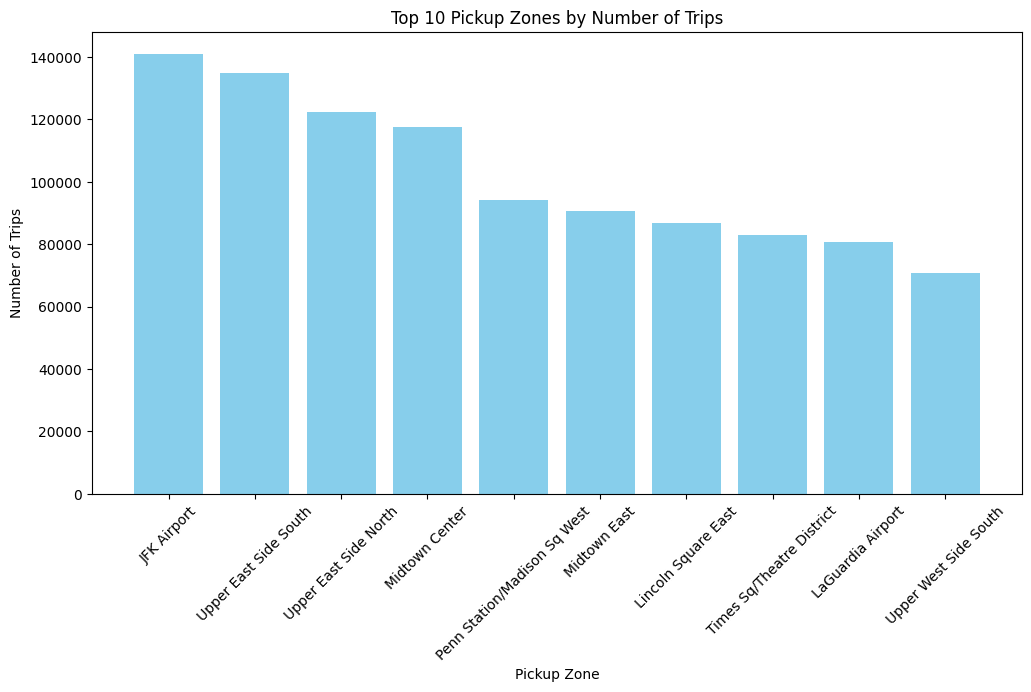

<Figure size 640x480 with 0 Axes>

In [402]:
#top pickup zones visualization
plt.figure(figsize=(12, 6))
plt.bar(
    top_pickup_zones["Zone"],
    top_pickup_zones["number_of_trips"],
    color="skyblue"
)
plt.title("Top 10 Pickup Zones by Number of Trips")
plt.xlabel("Pickup Zone")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)

plt.show()
plt.savefig("top_pickup_zones.png", dpi=300)

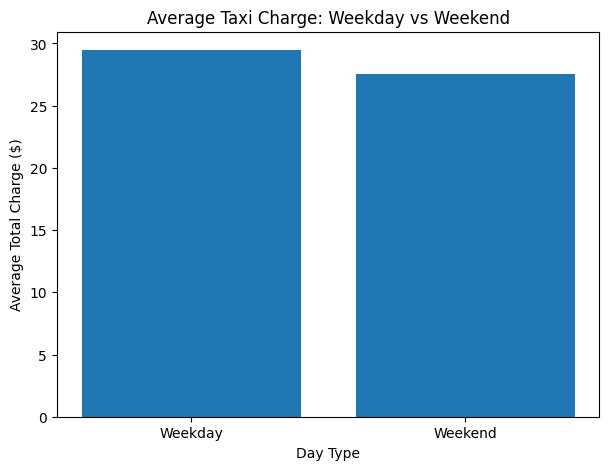

<Figure size 640x480 with 0 Axes>

In [401]:
#weekday vs weekend visualization
plt.figure(figsize=(7, 5))

plt.bar(
    weekday_weekend["day_type"],
    weekday_weekend["avg_total"]
)

plt.title("Average Taxi Charge: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Total Charge ($)")

plt.show()
plt.savefig("weekday_vs_weekend_avg_charge.png", dpi=300)

In [392]:
plt.savefig(
    "trips_by_hour.png",
    bbox_inches="tight",
    dpi=300
)

<Figure size 640x480 with 0 Axes>

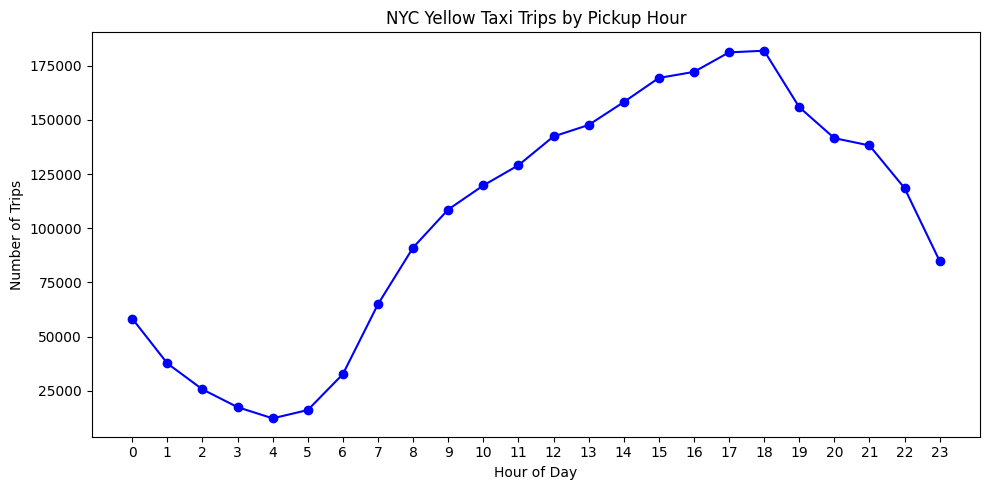

In [393]:
#visulization for trips by hour 
plt.figure(figsize=(10, 5))
plt.plot(
    trips_by_hour["pickup_hour"],
    trips_by_hour["number_of_trips"],
    marker="o",
    color="blue"
)
plt.title("NYC Yellow Taxi Trips by Pickup Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.xticks(range(24))
plt.tight_layout()
plt.savefig("trips_by_hour.png", dpi=300)

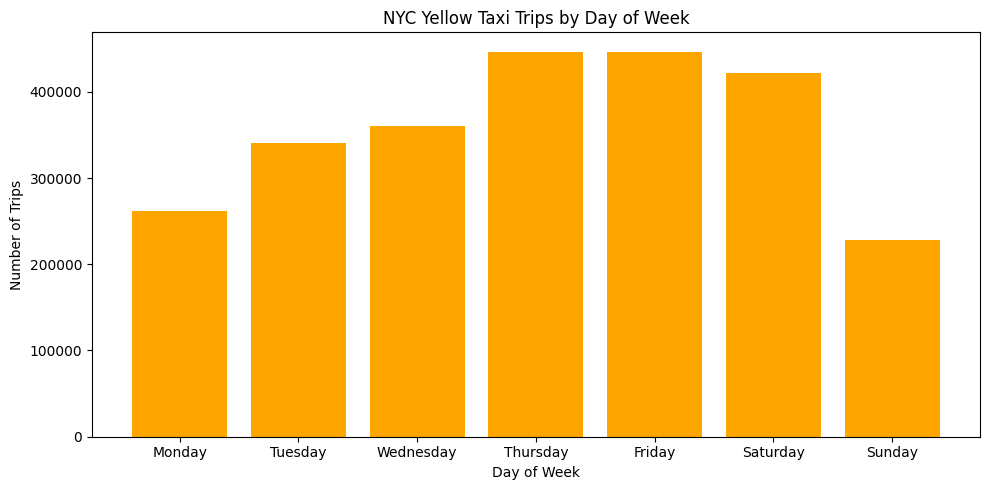

In [396]:
#trips by day of week visualization
plt.figure(figsize=(10, 5))
plt.bar(
    trips_by_day["day_name"],
    trips_by_day["number_of_trips"],
    color="orange"
)
plt.title("NYC Yellow Taxi Trips by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.savefig("trips_by_day.png", dpi=300)

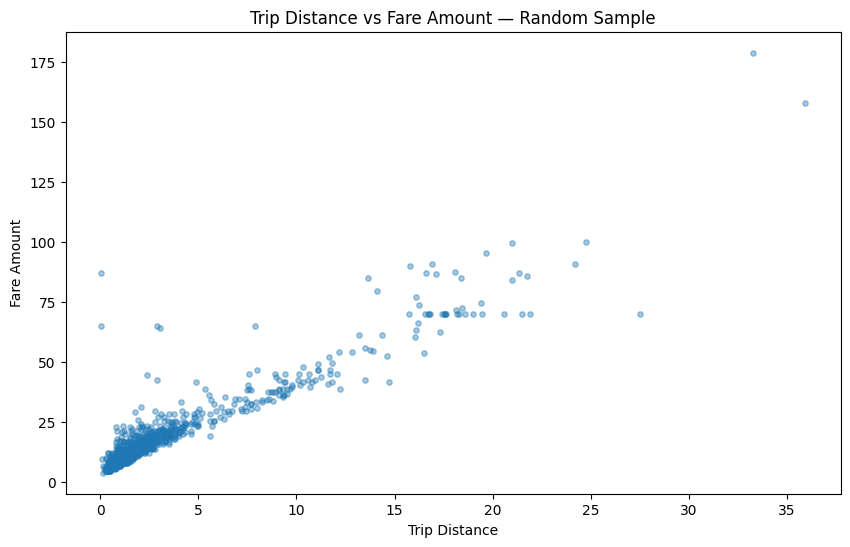

<Figure size 640x480 with 0 Axes>

In [400]:
#distance vs fare scatter plot (use a random sample of 1000 points for better visualization)
sample = df_clean[["trip_distance", "fare_amount"]].dropna()
sample = sample.sample(n=min(1000, len(sample)), random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(sample["trip_distance"], sample["fare_amount"], alpha=0.4, s=15)
plt.xlabel("Trip Distance")
plt.ylabel("Fare Amount")
plt.title("Trip Distance vs Fare Amount — Random Sample")
plt.show()
plt.savefig("distance_vs_fare.png", dpi=300)

We will start the ML model process from here using 4 feaure which are trip distance/duration, pickup hour and day of the week so that we can predict the fare amount 

In [403]:
features = [
    "trip_distance",
    "trip_duration_minutes",
    "pickup_hour",
    "day_of_week",
]

In [408]:
#since we dont need all 3 million data points for the model, we can take a random sample of 200,000 rows for training and testing
# Select model columns and remove rows with missing values
model_data = df_model[features + ["fare_amount"]].dropna()

# Randomly sample up to 200,000 rows for training and testing
model_data = model_data.sample(
    n=min(200000, len(model_data)),
    random_state=42
)

In [409]:
#create X and y for the model
X = model_data[features]
y = model_data["fare_amount"]

In [410]:
#create train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
#check the shapes of the training and testing sets so that we dont test on the same data we trained on
print(X_train.shape)
print(X_test.shape)

(160000, 4)
(40000, 4)


In [412]:
#start off with a simple linear regression model
linear_model = LinearRegression()


In [413]:
#train the linear regression model
linear_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [414]:
#predict on the test set
linear_predictions = linear_model.predict(X_test)

In [416]:
#look at actual vs predicted values for the first 10 rows
comparison_df = pd.DataFrame({
    "Actual Fare": y_test.values,
    "Predicted Fare": linear_predictions
})
comparison_df.head(10)

,Actual Fare,Predicted Fare
0,15.60,16.00
1,4.40,4.55
2,6.50,6.89
3,28.90,29.73
4,8.60,8.26
5,17.00,17.52
6,13.50,13.60
7,9.30,10.36
8,17.00,18.89
9,4.40,3.88


In [417]:
#evaluate the model's performance using metrics like Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²)
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_r2 = r2_score(y_test, linear_predictions)
print(f"Mean Absolute Error (MAE): {linear_mae:.2f}")
print(f"Mean Squared Error (MSE): {linear_mse:.2f}")
print(f"R-squared (R²): {linear_r2:.4f}")

Mean Absolute Error (MAE): 0.67
Mean Squared Error (MSE): 1.37
R-squared (R²): 0.9906


In [418]:
#lets look at the coeffeicients of the linear regression model to see how each feature contributes to the fare prediction
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": linear_model.coef_
})
coefficients
print("Intercepts:", linear_model.intercept_)

Intercepts: 2.4257537476955235


Lets now crate a random ofrest ML model

In [419]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [420]:
#train the random forest model
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [421]:
#predict on the test set for random forest
rf_predictions = rf_model.predict(X_test)


In [422]:
#evaluate the random forest model's performance using metrics like Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²)
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions) 

print("Random Forest model performance metrics:")
print(f"Random Forest Mean Absolute Error (MAE): {rf_mae:.2f}")
print(f"Random Forest Mean Squared Error (MSE): {rf_mse:.2f}")
print(f"Random Forest R-squared (R²): {rf_r2:.4f}")

Random Forest model performance metrics:
Random Forest Mean Absolute Error (MAE): 0.46
Random Forest Mean Squared Error (MSE): 0.83
Random Forest R-squared (R²): 0.9943


In [425]:
#comparing the performance of the two models
model_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "MSE": [linear_mse, rf_mse],
    "R-squared": [linear_r2, rf_r2]
})
model_results.round(4)

,Model,MAE,MSE,R-squared
0,Linear Regression,0.67,1.37,0.99
1,Random Forest,0.46,0.83,0.99


In [429]:
#calculate rmse since its in dollers 
linear_rmse = np.sqrt(linear_mse)
rf_rmse = np.sqrt(rf_mse)

print("Linear Regression RMSE: $",round(linear_rmse, 2))
print("Random Forest RMSE: $",round(rf_rmse, 2))

Linear Regression RMSE: $ 1.17
Random Forest RMSE: $ 0.91


In [431]:
#lets find out what the most important features are for the random forest model
feature_importances = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)
feature_importances

,Feature,Importance
0,trip_distance,0.78
1,trip_duration_minutes,0.22
2,pickup_hour,0.00
3,day_of_week,0.00


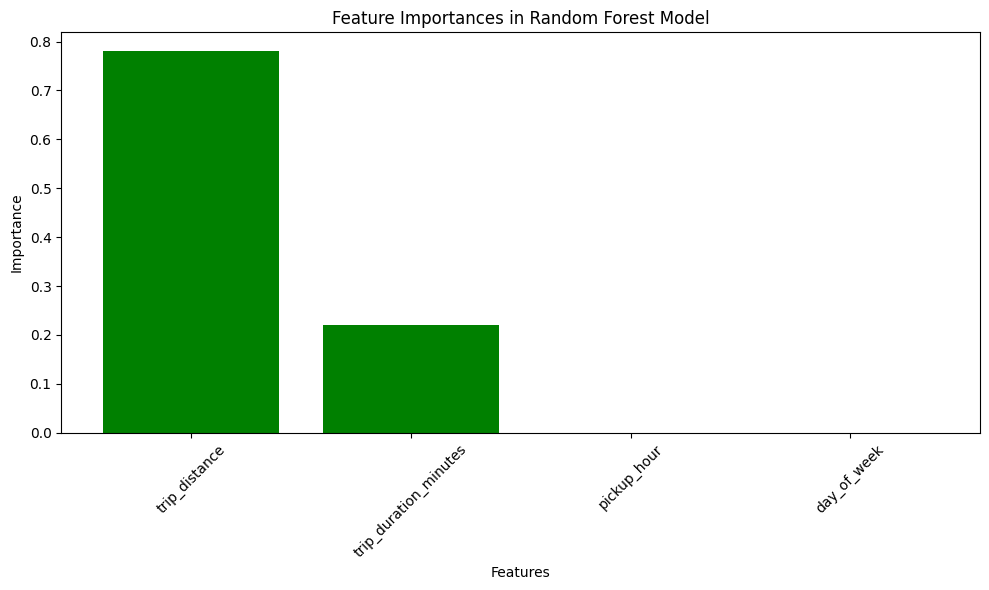

<Figure size 640x480 with 0 Axes>

In [432]:
#plot the feature importances for the random forest model
plt.figure(figsize=(10, 6))
plt.bar(
    feature_importances["Feature"],
    feature_importances["Importance"],
    color="green"
)
plt.title("Feature Importances in Random Forest Model")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.savefig("feature_importances_rf.png", dpi=300)

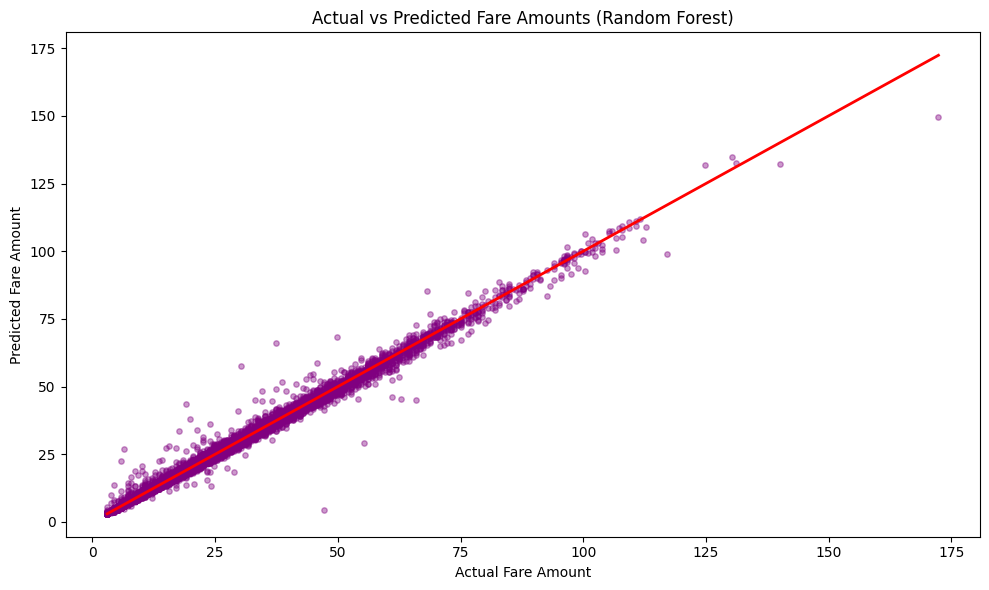

<Figure size 640x480 with 0 Axes>

In [433]:
#actual vs predicted fare for the random forest model
plt.figure(figsize=(10, 6))
plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.4,
    s=15,
    color="purple"
)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)
plt.title("Actual vs Predicted Fare Amounts (Random Forest)")
plt.xlabel("Actual Fare Amount")
plt.ylabel("Predicted Fare Amount")
plt.tight_layout()
plt.show()
plt.savefig("actual_vs_predicted_rf.png", dpi=300)

In [434]:
#since R2 is high check with just trip distance and trip duration to see if we can get a simpler model with similar performance
simple_features = ["trip_distance", "trip_duration_minutes"]


In [436]:
X_simple = model_data[simple_features]
X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)
rf_simple_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf_simple_model.fit(X_simple_train, y_simple_train)
simple_rf_predictions = rf_simple_model.predict(X_simple_test)

In [437]:
#evaluate the simpler random forest model's performance
simple_rf_mae = mean_absolute_error(y_simple_test, simple_rf_predictions)
simple_rf_mse = mean_squared_error(y_simple_test, simple_rf_predictions)
simple_rf_r2 = r2_score(y_simple_test, simple_rf_predictions)

print("Simpler Random Forest model performance metrics:")
print(f"Simpler Random Forest Mean Absolute Error (MAE): {simple_rf_mae:.2f}")
print(f"Simpler Random Forest Mean Squared Error (MSE): {simple_rf_mse:.2f}")
print(f"Simpler Random Forest R-squared (R²): {simple_rf_r2:.4f}")  

Simpler Random Forest model performance metrics:
Simpler Random Forest Mean Absolute Error (MAE): 0.47
Simpler Random Forest Mean Squared Error (MSE): 0.86
Simpler Random Forest R-squared (R²): 0.9941


In [438]:
#final comparison of all models
final_model_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Simpler Random Forest"],
    "MAE": [linear_mae, rf_mae, simple_rf_mae],
    "MSE": [linear_mse, rf_mse, simple_rf_mse],
    "R-squared": [linear_r2, rf_r2, simple_rf_r2]
})

final_model_results.round(4)

,Model,MAE,MSE,R-squared
0,Linear Regression,0.67,1.37,0.99
1,Random Forest,0.46,0.83,0.99
2,Simpler Random Forest,0.47,0.86,0.99


In [439]:
#calulate RMSE for the simpler random forest model
simple_rf_rmse = np.sqrt(simple_rf_mse)
print("Simpler Random Forest RMSE: $", round(simple_rf_rmse, 2))

Simpler Random Forest RMSE: $ 0.93


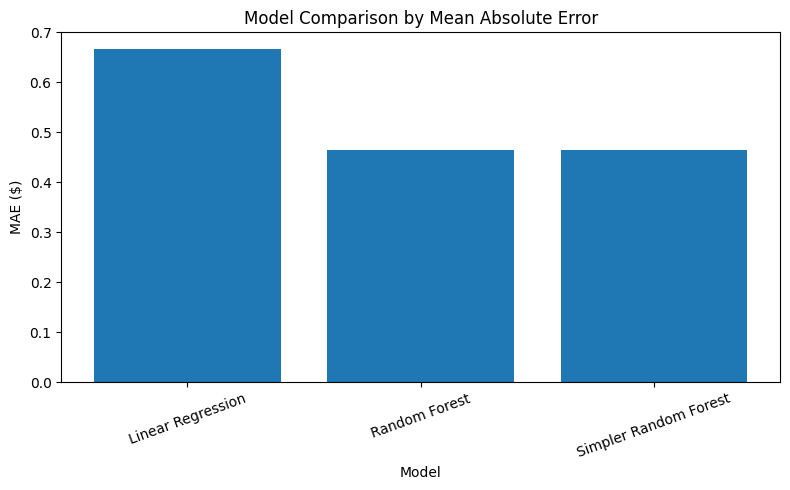

In [441]:
#comparing the performance of all three models visually
plt.figure(figsize=(8, 5))

plt.bar(
    final_model_results["Model"],
    final_model_results["MAE"]
)

plt.title("Model Comparison by Mean Absolute Error")
plt.xlabel("Model")
plt.ylabel("MAE ($)")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

# Machine Learning Results

Three models were evaluated for predicting NYC Yellow Taxi fares: Linear Regression, Random Forest using four features, and a simplified Random Forest using only trip distance and trip duration.

The Random Forest produced the best performance, with a mean absolute error of approximately $0.46 and an R² of approximately 0.99. Feature importance showed that trip distance accounted for approximately 78% of the model's importance and trip duration approximately 22%, while pickup hour and day of week contributed very little additional predictive value.

Removing pickup hour and day of week produced almost no reduction in performance, with MAE increasing from approximately $0.46 to $0.47. This suggests that trip distance and duration contain nearly all of the useful information required by these models to predict standard taxi fares.

## Key Findings
NYC Yellow Taxi demand varied substantially by time of day, with 6:00 PM recording the highest number of trips in the January 2026 dataset.

Trip distance and fare amount showed a strong positive relationship, indicating that longer trips generally result in higher fares.

The Random Forest model outperformed Linear Regression in fare prediction, reducing MAE from approximately $0.67 to $0.46.

Trip distance was the dominant predictor of fare (78% feature importance), followed by trip duration (22%).

Pickup hour and day of week provided almost no additional predictive value once distance and duration were known.

A simplified Random Forest using only distance and duration performed almost identically to the four-feature model, achieving an MAE of approximately $0.47.